### Cross-Conference Association Mining pada DBLP (2015–2025)
**Mining Cross-Conference Publication Associations in Computer Science (DBLP 2015–2025): Has the LLM Era Reshaped Community Structure?**

**Research questions**
- RQ1: Konferensi mana yang paling populer (jumlah paper vs jumlah author unik)?
- RQ2: Kombinasi konferensi mana yang paling sering muncul bersama, dan rule mana yang lift-nya tertinggi?
- RQ3: Apakah Author-Based dan Author-Year-Based menghasilkan pola berbeda?
- RQ4: Apriori atau FP-Growth, mana yang lebih sesuai untuk DBLP?
- RQ5: Apakah asosiasi antar-konferensi bergeser dari 2015–2017 ke 2024–2025 (era LLM)?

### Setup

In [1]:
# Instal library
!pip -q install lxml pyarrow mlxtend

# impor modul
import os, re, gzip, json, shutil, hashlib, time, unicodedata, urllib.request
import datetime as dt
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lxml import etree

# ---------- KONFIGURASI ----------
# Opsional: simpan data di Google Drive agar tidak diunduh ulang setiap sesi
#   from google.colab import drive; drive.mount("/content/drive")
#   DATA_DIR = "/content/drive/MyDrive/dblp_project"

# configuration
DATA_DIR   = "/content/dblp_project"
DBLP_URL   = "https://dblp.org/xml/dblp.xml.gz"   # untuk reproduksi persis, ganti ke rilis bertanggal di dblp.org/xml/release/
DTD_URL    = "https://dblp.org/xml/dblp.dtd"
YEAR_MIN, YEAR_MAX = 2015, 2025
MAX_RECORDS = None    ### changeable --> 200000 (fasten)
SEED = 42
# ---------------------------------

np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(f"{DATA_DIR}/clean", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50, "display.width", 160, "display.float_format", "{:,.2f}".format)
print("Library siap. DATA_DIR =", DATA_DIR)

Library siap. DATA_DIR = /content/dblp_project


### Task 1
### Data Understanding and Preprocessing
Sub-bagian:
   - 1.1 pengambilan data
   - 1.2 parsing dan eksplorasi
   - 1.3 preprocessing
   - 1.4 penjelasan langkah
   - 1.5 statistik setelah preprocessing.

## 1.1 Pengambilan Data (sumber, tanggal pengambilan, ukuran)

In [2]:
# Unduh dblp.xml.gz dan dblp.dtd, lalu catat tanggal pengambilan, ukuran file, dan checksum (spek C.5).
GZ_PATH, XML_PATH, DTD_PATH = f"{DATA_DIR}/dblp.xml.gz", f"{DATA_DIR}/dblp.xml", f"{DATA_DIR}/dblp.dtd"
META_PATH = f"{DATA_DIR}/metadata.json"

def fetch(url, dst):
    """Unduh url ke dst bila belum ada; kembalikan header Last-Modified (atau None)."""
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        print("sudah ada, lewati:", dst); return None
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (data-mining-course-project)"})
    with urllib.request.urlopen(req) as r, open(dst, "wb") as f:
        last_mod = r.headers.get("Last-Modified")
        shutil.copyfileobj(r, f, 1 << 20)
    print("terunduh:", dst, f"{os.path.getsize(dst)/1e6:,.1f} MB")
    return last_mod

def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while b := f.read(chunk): h.update(b)
    return h.hexdigest()

last_mod = fetch(DBLP_URL, GZ_PATH)
fetch(DTD_URL, DTD_PATH)

if not os.path.exists(META_PATH):           # metadata hanya ditulis sekali, saat pertama kali diunduh
    meta = {"source": DBLP_URL, "retrieved_at_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
            "last_modified_header": last_mod, "size_bytes": os.path.getsize(GZ_PATH), "sha256": sha256(GZ_PATH)}
    json.dump(meta, open(META_PATH, "w"), indent=2)
meta = json.load(open(META_PATH)); print(json.dumps(meta, indent=2))

if not os.path.exists(XML_PATH):            # lxml perlu file XML biasa di folder yang sama dengan dblp.dtd (untuk entitas seperti &uuml;)
    with gzip.open(GZ_PATH, "rb") as fi, open(XML_PATH, "wb") as fo:
        shutil.copyfileobj(fi, fo, 1 << 22)
print("XML siap:", XML_PATH, f"{os.path.getsize(XML_PATH)/1e9:,.2f} GB")

terunduh: /content/dblp_project/dblp.xml.gz 1,122.3 MB
terunduh: /content/dblp_project/dblp.dtd 0.0 MB
{
  "source": "https://dblp.org/xml/dblp.xml.gz",
  "retrieved_at_utc": "2026-11-20T05:56:35+00:00",
  "last_modified_header": "Thu, 19 Nov 2026 22:14:08 GMT",
  "size_bytes": 1122310554,
  "sha256": "0070082378b55f9db21293eef8a87de47181cbf60a9663b9749ba88fc5e816df"
}
XML siap: /content/dblp_project/dblp.xml 5.42 GB


## 1.2 Parsing dan Eksplorasi Dataset (struktur, atribut, jumlah record, jenis publikasi)

In [3]:
# hitung seluruh jenis record dan simpan inproceedings periode 2015-2025 sebagai data mentah.
SEP = "\u241f"    # pemisah author
RECORD_TAGS = ("article", "inproceedings", "proceedings", "book", "incollection", "phdthesis", "mastersthesis", "www", "data")

def text_of(el):
    """Teks lengkap sebuah elemen, termasuk teks di dalam tag bersarang seperti <i> atau <sub>."""
    return "".join(el.itertext()).strip() if el is not None else ""

def parse_dblp(xml_path, y0, y1, max_records=None):
    type_counts, field_presence, year_all = Counter(), Counter(), Counter()
    n_total = n_inproc = n_outside = 0
    rows, samples = [], []
    t0 = time.time()
    ctx = etree.iterparse(xml_path, events=("end",), tag=RECORD_TAGS,
                          load_dtd=True, resolve_entities=True, huge_tree=True)
    for _, el in ctx:
        n_total += 1
        type_counts[el.tag] += 1
        if el.tag == "inproceedings":
            n_inproc += 1
            field_presence.update({c.tag for c in el})
            if len(samples) < 3:
                samples.append(etree.tostring(el, encoding="unicode").strip())
            year_raw = text_of(el.find("year"))
            year_all[year_raw] += 1
            if year_raw.isdigit() and not (y0 <= int(year_raw) <= y1):
                n_outside += 1                       # tahun valid tetapi di luar periode: hanya dihitung
            else:                                    # di dalam periode, atau tahun kosong/tidak valid (ditangani saat preprocessing)
                rows.append((el.get("key"), text_of(el.find("title")), year_raw, text_of(el.find("booktitle")),
                             text_of(el.find("crossref")), SEP.join(text_of(a) for a in el.findall("author"))))
        el.clear()                                   # bebaskan memori
        while el.getprevious() is not None:
            del el.getparent()[0]
        if n_total % 1_000_000 == 0:
            print(f"  {n_total:,} record dibaca ({time.time()-t0:,.0f} dtk)")
        if max_records and n_total >= max_records:
            print("  MAX_RECORDS tercapai, parsing dihentikan (mode uji)"); break
    raw = pd.DataFrame(rows, columns=["key", "title", "year_raw", "booktitle", "crossref", "authors_raw"])
    info = dict(type_counts=type_counts, field_presence=field_presence, year_all=year_all,
                n_total=n_total, n_inproc=n_inproc, n_outside=n_outside, samples=samples)
    print(f"Selesai: {n_total:,} record, {len(raw):,} inproceedings dipertahankan ({time.time()-t0:,.0f} dtk)")
    return raw, info

raw, info = parse_dblp(XML_PATH, YEAR_MIN, YEAR_MAX, MAX_RECORDS)

# ---- Eksplorasi: struktur, atribut, jumlah record, jenis publikasi ----
types = pd.DataFrame({"jumlah": pd.Series(info["type_counts"])}).sort_values("jumlah", ascending=False)
types["persen"] = 100 * types["jumlah"] / types["jumlah"].sum()
print(f"\nTotal record: {info['n_total']:,}"); display(types)

fields = pd.DataFrame({"jumlah": pd.Series(info["field_presence"])}).sort_values("jumlah", ascending=False)
fields["persen_inproceedings"] = 100 * fields["jumlah"] / info["n_inproc"]
print("\nAtribut pada record inproceedings:"); display(fields)

yrs = pd.Series({int(y): n for y, n in info["year_all"].items() if y.isdigit()}).sort_index()
print(f"\nRentang tahun inproceedings di DBLP: {yrs.index.min()}-{yrs.index.max()}")
print(f"inproceedings total: {info['n_inproc']:,} | di luar {YEAR_MIN}-{YEAR_MAX}: {info['n_outside']:,} | dipertahankan (mentah): {len(raw):,}")
print("\nContoh record mentah:"); print(info["samples"][0])

  1,000,000 record dibaca (58 dtk)
  2,000,000 record dibaca (118 dtk)
  3,000,000 record dibaca (184 dtk)
  4,000,000 record dibaca (250 dtk)
  5,000,000 record dibaca (268 dtk)
  6,000,000 record dibaca (279 dtk)
  7,000,000 record dibaca (288 dtk)
  8,000,000 record dibaca (295 dtk)
  9,000,000 record dibaca (315 dtk)
  10,000,000 record dibaca (338 dtk)
  11,000,000 record dibaca (363 dtk)
  12,000,000 record dibaca (387 dtk)
  13,000,000 record dibaca (414 dtk)
Selesai: 13,132,145 record, 2,004,202 inproceedings dipertahankan (417 dtk)

Total record: 13,132,145


,jumlah,persen
article,4530293,34.50
www,4248758,32.35
inproceedings,4004309,30.49
phdthesis,158395,1.21
incollection,71264,0.54
proceedings,65903,0.50
data,31542,0.24
book,21654,0.16
mastersthesis,27,0.00



Atribut pada record inproceedings:


,jumlah,persen_inproceedings
url,4004309,100.00
title,4004309,100.00
year,4004309,100.00
booktitle,4003988,99.99
crossref,4001700,99.93
author,3998226,99.85
ee,3866931,96.57
pages,3774627,94.26
stream,185903,4.64
cdrom,8482,0.21



Rentang tahun inproceedings di DBLP: 1951-2027
inproceedings total: 4,004,309 | di luar 2015-2025: 2,000,107 | dipertahankan (mentah): 2,004,202

Contoh record mentah:
<inproceedings mdate="2022-10-02" key="series/sapere/Freed13">
<author orcid="0000-0002-4182-3228">Sam Freed</author>
<title>Practical Introspection as Inspiration for AI.</title>
<pages>167-177</pages>
<year>2011</year>
<booktitle>PT-AI</booktitle>
<ee>https://doi.org/10.1007/978-3-642-31674-6_12</ee>
<crossref>series/sapere/2013-5</crossref>
<url>db/series/sapere/sapere5.html#Freed13</url>
</inproceedings>


**Interpretasi eksplorasi** *(isi setelah dijalankan)*: jenis record yang tersedia dan proporsinya; atribut yang selalu ada vs yang kadang kosong pada `inproceedings`; berapa banyak record yang berada di luar 2015–2025.

## 1.3 Preprocessing

In [4]:
# Preprocessing berurutan (missing, tahun, front matter, venue, author, duplikat); setiap langkah dicatat jumlah record-nya.
funnel = [("inproceedings dalam periode (mentah)", len(raw))]
def step(name, df):
    funnel.append((name, len(df)))
    print(f"{name:55s} {len(df):>12,}")
    return df

df = raw.copy()
for c in ["key", "title", "year_raw", "booktitle", "crossref", "authors_raw"]:
    df[c] = df[c].fillna("").map(lambda s: re.sub(r"\s+", " ", unicodedata.normalize("NFKC", s)).strip())

# 1) Missing values: record tanpa key, judul, tahun, atau author tidak dapat dipakai
df = step("1. hapus missing (key/title/year/author)",
          df[(df.key != "") & (df.title != "") & (df.year_raw != "") & (df.authors_raw != "")].copy())

# 2) Konsistensi tahun: ubah ke integer, buang yang tidak valid atau di luar periode
df["year"] = pd.to_numeric(df["year_raw"], errors="coerce")
df = step("2. tahun valid & dalam periode",
          df[df.year.between(YEAR_MIN, YEAR_MAX)].astype({"year": "int16"}).copy())
cr_year = df["crossref"].str.extract(r"/((?:19|20)\d{2})")[0].astype("float")   # tahun pada key proceedings, bila ada
mismatch = int((cr_year.notna() & (cr_year != df["year"])).sum())
print(f"   catatan: {mismatch:,} record bertahun beda dari tahun proceedings (crossref); tahun <year> DBLP tetap dipakai")

# 3) Front matter / non-paper (kata pengantar, daftar isi, dsb.) tidak mewakili aktivitas riset
FRONT = re.compile(r"^(preface|foreword|front matter|back matter|table of contents|contents|author index|index|"
                   r"program committee|organi[sz]ing committee|reviewers?|sponsors?|welcome( message)?|"
                   r"message from .{0,80}|editorial|proceedings)\b[^.]{0,60}$", re.I)
is_front = df.title.map(lambda t: bool(FRONT.match(t)))
print("   contoh judul yang dibuang:", df.title[is_front].head(5).tolist())
df = step("3. buang front matter", df[~is_front].copy())

# 4) Normalisasi venue: pakai segmen venue pada key DBLP (conf/<venue>/...), bukan booktitle yang bervariasi
VENUE_ALIAS = {"nips": "neurips"}      # tambahkan alias lain bila ditemukan venue yang terpecah
def venue_of(key, booktitle):
    p = key.split("/")
    if len(p) >= 3 and p[0] == "conf" and p[1]:
        v = p[1].lower()
    else:                               # cadangan: bersihkan booktitle (hapus tahun, ordinal, kata umum)
        b = re.sub(r"\(.*?\)", " ", booktitle.lower())
        b = re.sub(r"\b(19|20)\d{2}\b|\b\d+(st|nd|rd|th)\b", " ", b)
        b = re.sub(r"\b(proceedings|proc|of|the|annual|international|conference|workshop|symposium|on)\b", " ", b)
        v = re.sub(r"[^a-z0-9]+", "-", b).strip("-")
    return VENUE_ALIAS.get(v, v).upper()
df["venue"] = [venue_of(k, b) for k, b in zip(df.key, df.booktitle)]
via_fallback = int((~df.key.str.startswith("conf/")).sum())
df = step("4. normalisasi venue (hapus venue kosong)", df[df.venue != ""].copy())
print(f"   {via_fallback:,} record memakai venue dari booktitle (key bukan conf/...)")
variants = df.groupby("venue").booktitle.nunique().sort_values(ascending=False)
print("   variasi penulisan booktitle per venue (alasan memakai key):"); display(variants.head(5).to_frame("jumlah_variasi_booktitle"))

# 5) Normalisasi author: Unicode NFKC + spasi sudah dilakukan; hapus author duplikat dalam satu paper
#    Sufiks angka DBLP ("Nama 0001") DIPERTAHANKAN karena menandai orang berbeda bernama sama.
def clean_authors(s):
    seen, out = set(), []
    for a in s.split(SEP):
        a = a.strip()
        if a and a not in seen:
            seen.add(a); out.append(a)
    return out
df["authors"] = df.authors_raw.map(clean_authors)
df = step("5. normalisasi author (buang paper tanpa author valid)", df[df.authors.map(len) > 0].copy())

# 6) Duplikat: (a) key yang sama, (b) isi sama (judul ternormalisasi + tahun + venue + himpunan author)
df = step("6a. hapus duplikat berdasarkan key", df.drop_duplicates("key").copy())
sig = (df.title.str.casefold().str.replace(r"[^a-z0-9]+", "", regex=True) + "|" + df.year.astype(str) + "|" + df.venue + "|"
       + df.authors.map(lambda a: ";".join(sorted(a))))
df = step("6b. hapus duplikat berdasarkan isi", df[~sig.duplicated()].copy())

# ---- Simpan data bersih (dipakai Task 2 dst.) ----
df = df.reset_index(drop=True); df["pid"] = df.index.astype("int32"); df["n_authors"] = df.authors.map(len).astype("int16")
papers = df[["pid", "key", "title", "year", "venue", "n_authors"]].copy()
papers["venue"] = papers["venue"].astype("category")
pa = df[["pid", "authors"]].explode("authors").rename(columns={"authors": "author"}).reset_index(drop=True)
pa["author"] = pa["author"].astype("category")
papers.to_parquet(f"{DATA_DIR}/clean/papers.parquet"); pa.to_parquet(f"{DATA_DIR}/clean/paper_author.parquet")
print(f"\nTersimpan: papers {papers.shape}, paper_author {pa.shape}")

funnel_df = pd.DataFrame(funnel, columns=["langkah", "jumlah_record"])
funnel_df["dibuang"] = -funnel_df.jumlah_record.diff().fillna(0).astype(int)
display(funnel_df)

1. hapus missing (key/title/year/author)                   2,001,947
2. tahun valid & dalam periode                             2,001,947
   catatan: 2,666 record bertahun beda dari tahun proceedings (crossref); tahun <year> DBLP tetap dipakai
   contoh judul yang dibuang: ['Welcome from the CICC Committee!']
3. buang front matter                                      2,001,946
4. normalisasi venue (hapus venue kosong)                  2,001,946
   3,161 record memakai venue dari booktitle (key bukan conf/...)
   variasi penulisan booktitle per venue (alasan memakai key):


,jumlah_variasi_booktitle
venue,
MICCAI,165
ECCV,114
ICSE,98
BIRTHDAY,90
HCI,86


5. normalisasi author (buang paper tanpa author valid)     2,001,946
6a. hapus duplikat berdasarkan key                         2,001,946
6b. hapus duplikat berdasarkan isi                         2,000,738

Tersimpan: papers (2000738, 6), paper_author (7880272, 2)


,langkah,jumlah_record,dibuang
0,inproceedings dalam periode (mentah),2004202,0
1,1. hapus missing (key/title/year/author),2001947,2255
2,2. tahun valid & dalam periode,2001947,0
3,3. buang front matter,2001946,1
4,4. normalisasi venue (hapus venue kosong),2001946,0
5,5. normalisasi author (buang paper tanpa autho...,2001946,0
6,6a. hapus duplikat berdasarkan key,2001946,0
7,6b. hapus duplikat berdasarkan isi,2000738,1208


## Task 1.4 — Penjelasan Tahapan Preprocessing dan Alasannya

| # | Tahap | Metode | Alasan |
|---|---|---|---|
| 0 | Seleksi publikasi | Hanya tag `inproceedings` (konferensi dan workshop), tahun 2015–2025, dipilih saat parsing | Sesuai ketentuan dataset; parsing streaming menghemat memori (file DBLP beberapa GB) |
| 1 | Missing values | Buang record tanpa `key`, judul, tahun, atau author | Tanpa author atau venue, record tidak bisa menjadi item transaksi; imputasi tidak bermakna untuk nama dan judul |
| 2 | Konsistensi tahun | Konversi ke integer, buang tahun tidak valid atau di luar periode; laporkan selisih dengan tahun proceedings | Tahun dipakai untuk transaksi Author-Year dan periode temporal; tahun `<year>` DBLP dipakai sebagai acuan tunggal |
| 3 | Front matter | Buang judul seperti preface, table of contents, author index | Bukan karya riset, sehingga menggembungkan aktivitas venue |
| 4 | Normalisasi venue | Ambil segmen venue dari `key` (`conf/<venue>/...`), huruf besar, alias (mis. `nips` → `NEURIPS`); cadangan: bersihkan `booktitle` | `booktitle` memiliki banyak variasi penulisan (lihat tabel variasi di 1.3), sedangkan `key` stabil di semua tahun |
| 5 | Normalisasi author | Unicode NFKC, rapikan spasi, buang author duplikat dalam satu paper; **sufiks angka DBLP dipertahankan** | DBLP sudah mendisambiguasi nama kembar dengan sufiks (`Nama 0001`); membuangnya akan menggabungkan orang berbeda |
| 6 | Duplikat | (a) `key` sama; (b) judul ternormalisasi + tahun + venue + himpunan author sama | Dilakukan setelah normalisasi agar varian penulisan ikut tergabung; mencegah satu paper dihitung dua kali |

*Catatan:* normalisasi author tidak menyatukan alias orang yang sama dengan ejaan berbeda (butuh data person record DBLP); ini dicatat sebagai keterbatasan.

## 1.5 Statistik Dataset Setelah Preprocessing

                                  nilai
Total publikasi            2,000,738.00
Total author unik          1,822,783.00
Total venue unik               4,494.00
Rata-rata author per paper         3.94
Maks author per paper            279.00


,jumlah_paper
year,
2015,161287
2016,162110
2017,168110
2018,176579
2019,188760
2020,172032
2021,178444
2022,178340
2023,201711


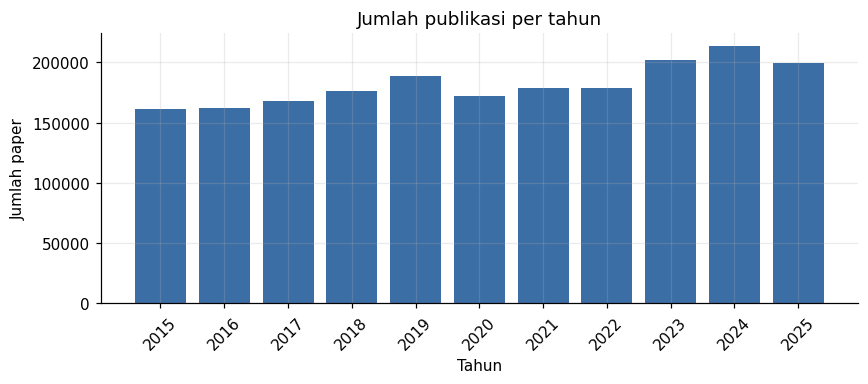

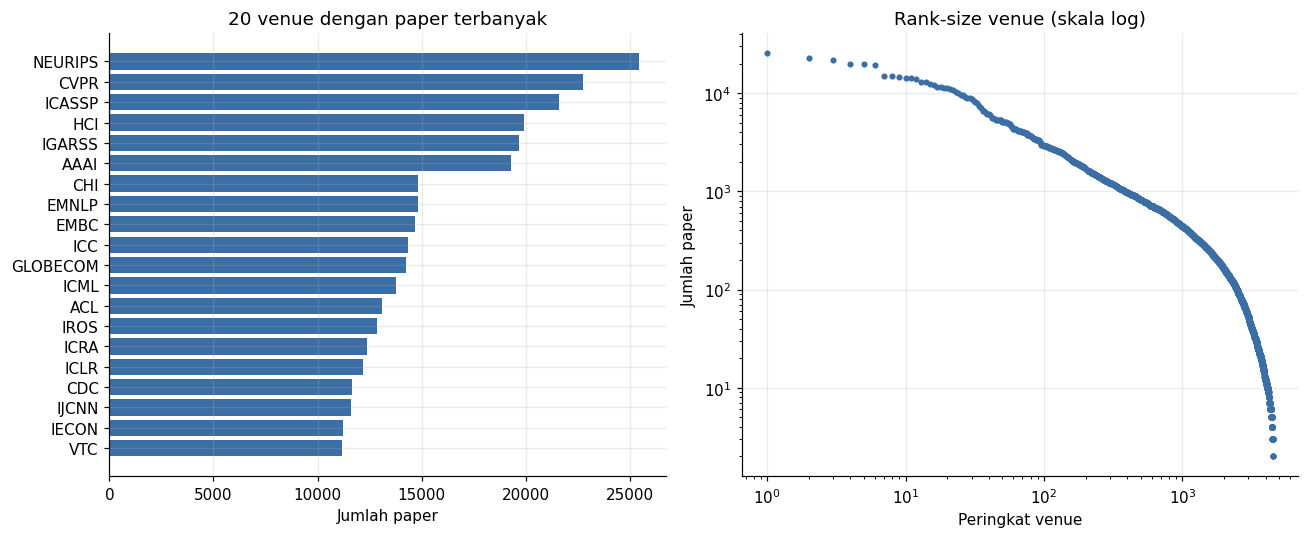

,ambang_min_paper,venue_tersisa,persen_paper_tercakup
0,1,4494,100.00
1,20,3700,99.58
2,50,3028,98.50
3,100,2480,96.51
4,200,1792,91.54
5,500,894,77.17
6,1000,385,59.30


,jumlah_paper
venue,
NEURIPS,25455
CVPR,22752
ICASSP,21606
HCI,19912
IGARSS,19685
AAAI,19276
CHI,14834
EMNLP,14814
EMBC,14677


In [5]:
# Tampilkan statistik dataset bersih: total paper, author unik, venue unik, distribusi per tahun dan per venue.
n_papers, n_authors, n_venues = len(papers), pa.author.nunique(), papers.venue.nunique()
print(pd.Series({"Total publikasi": n_papers, "Total author unik": n_authors, "Total venue unik": n_venues,
                 "Rata-rata author per paper": papers.n_authors.mean(), "Maks author per paper": papers.n_authors.max()}).to_frame("nilai"))

by_year = papers.groupby("year").size().rename("jumlah_paper")
by_venue = papers.groupby("venue", observed=True).size().sort_values(ascending=False).rename("jumlah_paper")
display(by_year.to_frame())

# (plot) distribusi paper per tahun
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(by_year.index.astype(str), by_year.values, color="#3b6ea5")
ax.set(title="Jumlah publikasi per tahun", xlabel="Tahun", ylabel="Jumlah paper"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# (plot) 20 venue teratas dan kurva rank-size (ekor panjang)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top = by_venue.head(20)[::-1]
axes[0].barh(top.index.astype(str), top.values, color="#3b6ea5"); axes[0].set(title="20 venue dengan paper terbanyak", xlabel="Jumlah paper")
axes[1].loglog(np.arange(1, len(by_venue) + 1), by_venue.values, ".", color="#3b6ea5")
axes[1].set(title="Rank-size venue (skala log)", xlabel="Peringkat venue", ylabel="Jumlah paper")
plt.tight_layout(); plt.show()

# Berapa venue dan berapa persen paper yang tersisa bila ambang minimal paper per venue dipakai? (bahan keputusan Task 3)
thr = pd.DataFrame([{"ambang_min_paper": t, "venue_tersisa": int((by_venue >= t).sum()),
                     "persen_paper_tercakup": 100 * by_venue[by_venue >= t].sum() / n_papers} for t in (1, 20, 50, 100, 200, 500, 1000)])
display(thr)
display(by_venue.head(20).to_frame())

**Interpretasi statistik** *(isi setelah dijalankan)*: ukuran dataset akhir; apakah paper per tahun naik; apakah distribusi venue berekor panjang; **keputusan ambang minimal paper per venue** untuk item transaksi (lihat tabel ambang di atas) dan alasannya.

# Task 2
## Conference Popularity Analysis
Yang harus dijawab: venue paling populer menurut jumlah publikasi; apakah venue itu juga punya author unik terbanyak; bagaimana aktivitas berubah 2015–2025.

**Interpretasi** *(isi setelah hasil keluar)*:

In [ ]:
# Hitung jumlah publikasi per venue dan tampilkan 10 venue teratas.
# (plot: bar horizontal top-10 venue menurut jumlah publikasi)

In [ ]:
# Hitung jumlah author unik per venue dan tampilkan 10 venue teratas.
# (plot: bar horizontal top-10 venue menurut jumlah author unik)

In [ ]:
# Hitung jumlah publikasi per venue per tahun untuk venue teratas (2015-2025).
# (plot: line chart tren per tahun, satu garis per venue)

In [ ]:
# Bandingkan ranking jumlah publikasi vs jumlah author unik (selisih peringkat, korelasi Spearman).
# (plot: scatter peringkat publikasi vs peringkat author unik, beri label venue yang selisihnya besar)

# Task 3 — Transactional Database Construction
Dua representasi: **A. Author-Based** (1 transaksi = 1 author, item = venue yang pernah ia terbitkan) dan **B. Author-Year-Based** (1 transaksi = 1 pasangan author-tahun).
Keputusan yang harus dicatat: ambang minimal paper per venue untuk item (dari Task 1.5); penanganan transaksi satu item.

**Interpretasi** *(isi)*: perbedaan kedua representasi, serta kelebihan dan keterbatasan masing-masing untuk Frequent Pattern Mining.

In [ ]:
# Bentuk Author-Based transactional database dari data bersih (author -> himpunan venue).

In [ ]:
# Bentuk Author-Year-Based transactional database dari data bersih ((author, tahun) -> himpunan venue).

In [ ]:
# Tampilkan minimal 10 contoh transaksi dari masing-masing representasi.

In [ ]:
# Hitung jumlah transaksi, jumlah item unik, dan ringkasan item per transaksi untuk kedua database.
# (plot: histogram distribusi jumlah item per transaksi, kedua representasi berdampingan, skala log pada sumbu y)

In [ ]:
# Susun tabel perbandingan kedua representasi (ukuran, kepadatan, proporsi transaksi satu item).

# Task 4 — Frequent Pattern Mining
Pada Author-Based database; min support **0,1% · 0,5% · 1% · 2%**.
Untuk tiap eksperimen: temukan frequent itemsets, identifikasi 1-/2-/3-itemset, top-10 berdasarkan support, analisis pengaruh min support, dan kombinasi venue yang paling sering muncul bersama.

**Interpretasi** *(isi)*: pengaruh min support terhadap jumlah itemset; arti kombinasi venue teratas.

In [ ]:
# Implementasikan Apriori sendiri (generate kandidat, pruning anti-monoton, hitung support).

In [ ]:
# Implementasikan FP-Growth sendiri (bangun FP-tree, mining conditional pattern base).

In [ ]:
# Validasi kedua implementasi terhadap mlxtend pada sampel kecil (himpunan itemset dan support harus sama).

In [ ]:
# Jalankan kedua algoritma pada min support 0,1%, 0,5%, 1%, 2% dan simpan hasilnya.

In [ ]:
# Hitung jumlah frequent 1-, 2-, dan 3-itemset untuk setiap min support.

In [ ]:
# Tampilkan 10 frequent itemsets dengan support tertinggi untuk setiap min support.

In [ ]:
# Buat grafik jumlah frequent itemsets terhadap min support.
# (plot: line chart dengan sumbu y logaritmik, satu garis per ukuran itemset)

In [ ]:
# Identifikasi kombinasi venue (itemset ukuran >= 2) yang paling sering muncul bersama.

# Task 5 — Association Rule Mining
Min confidence **50%**; hitung support, confidence, dan lift; ambil 10 rule dengan lift tertinggi.
Yang harus dijawab: hubungan asosiasi yang menarik; apakah support tinggi selalu berarti lift tinggi; beda interpretasi support, confidence, lift; pola publikasi antar-konferensi.

**Interpretasi** *(isi)*:

In [ ]:
# Bangkitkan association rules dari frequent itemsets (antecedent -> consequent) dengan min confidence 50%.

In [ ]:
# Hitung support, confidence, dan lift untuk setiap rule lalu tampilkan tabelnya.

In [ ]:
# Tampilkan 10 rule dengan lift tertinggi.

In [ ]:
# Periksa hubungan support itemset dengan lift (korelasi Spearman) untuk menjawab apakah support tinggi selalu lift tinggi.
# (plot: scatter support vs lift, warna menurut confidence)

# Task 6 — Algorithm Performance Comparison
Bandingkan Apriori dan FP-Growth pada database dan min support yang sama, berdasarkan jumlah frequent itemsets dan jumlah association rules.
Yang harus dijawab: pengaruh min support; apakah hasil kedua algoritma sama; algoritma mana yang lebih sesuai untuk DBLP dan alasannya.

**Interpretasi** *(isi)*:

In [ ]:
# Jalankan kedua algoritma untuk setiap min support dan catat jumlah frequent itemsets serta jumlah rules.
# (opsional, tambahan di luar spek: catat juga waktu eksekusi dan puncak memori)

In [ ]:
# Periksa apakah himpunan frequent itemsets Apriori dan FP-Growth identik untuk setiap min support.

In [ ]:
# Visualisasikan perbandingan kedua algoritma terhadap min support.
# (plot: grouped bar jumlah itemset dan jumlah rules; jika waktu dicatat, line chart waktu vs min support)

# Task 7 — Temporal Association Analysis (Bagian E spek)
Periode: **2015–2017 · 2018–2020 · 2021–2023 · 2024–2025**, memakai Author-Year-Based database.
Yang harus dijawab: itemset dan rules tiap periode; pola yang bertahan vs berubah; kemungkinan perubahan tren publikasi (**RQ5**, hati-hati: asosiasi bukan kausalitas).

**Interpretasi** *(isi)*:

In [ ]:
# Bagi Author-Year-Based database menjadi empat periode dan hitung ukuran transaksi tiap periode.

In [ ]:
# Jalankan frequent pattern mining pada setiap periode dengan min support yang sama dan simpan itemsetnya.

In [ ]:
# Bangkitkan association rules untuk setiap periode (min confidence 50%).

In [ ]:
# Bandingkan rules antar-periode: rule yang bertahan, baru muncul, hilang, dan perubahan lift pada rule yang sama.
# (plot: heatmap lift rule kunci per periode, atau diagram batang rule bertahan/baru/hilang per transisi periode)

In [ ]:
# Ringkas pergeseran per kelompok venue (mis. NLP, ML umum, CV) untuk menguji RQ5; kelompok didefinisikan manual dan dilaporkan di lampiran.
# (plot: line chart kekuatan asosiasi antar-kelompok venue per periode)

# Task 8 — Kesimpulan, Keterbatasan, dan Asumsi
Jawab berdasarkan hasil eksperimen (catatan spek bagian H). Isi setelah Task 2–7 selesai.

1. Konferensi dengan popularitas publikasi tertinggi: *(isi)*
2. Apakah konferensi terpopuler juga punya asosiasi terkuat dengan konferensi lain: *(isi)*
3. Kombinasi konferensi yang paling sering muncul bersama: *(isi)*
4. Rule dengan lift tertinggi dan maknanya: *(isi)*
5. Beda pola Author-Based vs Author-Year-Based: *(isi)*
6. Algoritma dengan performa terbaik: *(isi)*
7. Insight utama (termasuk jawaban RQ5): *(isi)*

**Keterbatasan dan asumsi** *(isi)*: popularitas diukur dari aktivitas publikasi, disambiguasi author mengikuti DBLP, ambang minimal paper per venue, asosiasi bukan kausalitas, batas komputasi Colab.

**Referensi** *(isi)*: DBLP, Agrawal & Srikant (Apriori), Han et al. (FP-Growth), pustaka yang dipakai.

In [ ]:
# Kumpulkan angka kunci dari Task 2-7 ke satu tabel ringkasan untuk laporan dan presentasi.